In [5]:
#Lab2: Training Neural Networks with Backpropagation and Gradient Descent
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

In [6]:
df = pd.read_csv("/content/smartcart_dataset (1).csv")
FEATURES = ["price", "weight_kg","rating", "discount_pct", "description_length"]

TARGET = "category"
df.head()

,price,weight_kg,rating,discount_pct,description_length,category
0,438.29,3.413,4.1,57.5,47,Apparel
1,719.57,6.111,3.5,46.5,45,Apparel
2,1202.48,9.337,4.1,23.7,109,Electronics
3,316.98,2.752,4.4,21.9,20,Grocery
4,2037.38,6.407,3.6,14.1,93,Electronics


In [7]:
X = df[FEATURES].values
y_raw = df[TARGET].values

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_

# Split data into training & testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert data into Tensors
X_train_tf = tf.convert_to_tensor(X_train_scaled, dtype=tf.float32)
y_train_tf = tf.convert_to_tensor(y_train, dtype=tf.int32)

X_test_tf = tf.convert_to_tensor(X_test_scaled, dtype=tf.float32)
y_test_tf = tf.convert_to_tensor(y_test, dtype=tf.int32)

In [8]:
model = Sequential()

model.add(Dense(32, activation="relu", input_dim=X_train_scaled.shape[1]))
model.add(Dense(16, activation="relu"))
model.add(Dense(3, activation="softmax"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
def forward(model, X):
    return model(X, training=True)

In [10]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()
def compute_loss(y_true, y_pred):
    return loss_fn(y_true, y_pred)

In [11]:
def backward(model, X, y_true):
    with tf.GradientTape() as tape:
        y_pred = forward(model, X)
        loss = compute_loss(y_true, y_pred)

    gradients = tape.gradient(loss, model.trainable_variables)
    return loss, gradients

In [12]:
optimizer = keras.optimizers.SGD(learning_rate=0.1)

def update(model, gradients, optimizer):
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

Epoch    0 │ Loss: 1.3088
Epoch   50 │ Loss: 0.3318
Epoch  100 │ Loss: 0.2303
Epoch  150 │ Loss: 0.1989
Epoch  200 │ Loss: 0.1825
Epoch  250 │ Loss: 0.1722
Epoch  300 │ Loss: 0.1648
Epoch  350 │ Loss: 0.1593
Epoch  400 │ Loss: 0.1549
Epoch  450 │ Loss: 0.1515


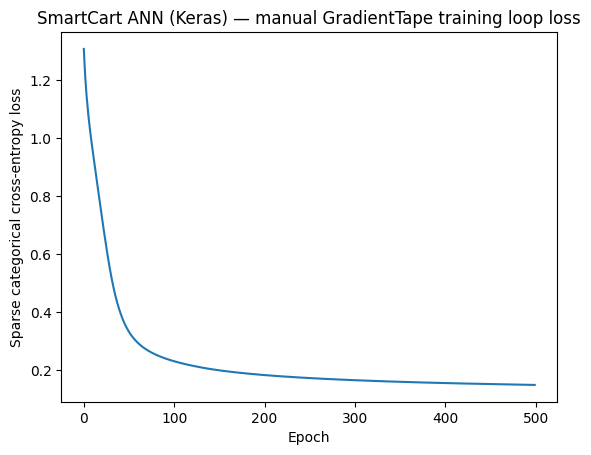

In [13]:
loss_history = []
for epoch in range(500):
    loss, gradients = backward(model, X_train_tf, y_train_tf)
    update(model, gradients, optimizer)

    loss_history.append(float(loss))

    if epoch % 50 == 0:
        print(f"Epoch {epoch:4d} │ Loss: {float(loss):.4f}")
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy loss")
plt.title("SmartCart ANN (Keras) — manual GradientTape training loop loss")
plt.show()

In [14]:
test_probs = model(X_test_tf, training=False)       # no training here

y_pred = np.argmax(test_probs.numpy(), axis=1)      # highest-probability class

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

Test accuracy: 0.9375
